In [1]:
import numpy as np
import pandas as pd

In [2]:
!pip install -qU ydata-profiling

In [3]:
audible = pd.read_csv("audible_uncleaned.csv")

In [4]:
audible.head()

,name,author,narrator,time,releasedate,language,stars,price
0,Geronimo Stilton #11 & #12,Writtenby:GeronimoStilton,Narratedby:BillLobely,2 hrs and 20 mins,04-08-08,English,5 out of 5 stars34 ratings,468.00
1,The Burning Maze,Writtenby:RickRiordan,Narratedby:RobbieDaymond,13 hrs and 8 mins,01-05-18,English,4.5 out of 5 stars41 ratings,820.00
2,The Deep End,Writtenby:JeffKinney,Narratedby:DanRussell,2 hrs and 3 mins,06-11-20,English,4.5 out of 5 stars38 ratings,410.00
3,Daughter of the Deep,Writtenby:RickRiordan,Narratedby:SoneelaNankani,11 hrs and 16 mins,05-10-21,English,4.5 out of 5 stars12 ratings,615.00
4,"The Lightning Thief: Percy Jackson, Book 1",Writtenby:RickRiordan,Narratedby:JesseBernstein,10 hrs,13-01-10,English,4.5 out of 5 stars181 ratings,820.00


In [5]:
audible.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87489 entries, 0 to 87488
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   name         87489 non-null  object
 1   author       87489 non-null  object
 2   narrator     87489 non-null  object
 3   time         87489 non-null  object
 4   releasedate  87489 non-null  object
 5   language     87489 non-null  object
 6   stars        87489 non-null  object
 7   price        87489 non-null  object
dtypes: object(8)
memory usage: 5.3+ MB


**Audible Dataset Columns**  

- Name: Name of the audiobook
- Author: Author of the audiobook
- Narrator: Narrator of the audiobook
- Time: Length of the audiobook
- Release Date: Release date of the audiobook
- Language: Language of the audiobook
- Stars: No. of stars the audiobook received
- Price: Price of the audiobook in INR

## Beoordeling van de data

Eerst inspecteren we de dataset handmatig. Daartoe laden we onze dataset in een Excel-sheet om deze te onderzoeken. Bij het handmatig onderzoeken van de data is het aan te raden om eerst de kolommen te bekijken, te controleren op datatypes, waarden en eventuele inconsistenties of uitschieters in de dataset, en daarna verder te gaan met het controleren van individuele observaties voor meer inzichten. Tijdens het uitvoeren van de handmatige beoordeling is het cruciaal om de structuur van de data te controleren.

### Vaststellingen tijdens de beoordeling

**Problemen gevonden bij Handmatige Beoordeling:**

- De kolom 'author' heeft een 'Written by' suffix die niet nuttig is.
- De kolom 'narrator' heeft een 'Narrated by' prefix voor de naam van de verteller die niet nuttig is.
- Tijd wordt opgeslagen in objectformaat (bijv. 2hrs and 34mins), wat niet geschikt is voor wiskundige bewerkingen.
- Datum is opgeslagen in een ongeschikt formaat.
- De kolom 'language' bevat inconsistenties; sommige talen hebben een hoofdletter aan het begin, terwijl anderen dat niet hebben.
- De kolom 'price' bevat waarden zoals 'free', wat niet geldig is voor numerieke gegevens.

**Problemen gevonden bij Automatische Beoordeling:** (.info)

- 'price' is opgeslagen in een ongeschikt formaat (object).
- 'releasedate' is opgeslagen in een ongeschikt formaat (object).
- 'language' is opgeslagen in een ongeschikt formaat (object). Dit zou als categorie moeten zijn opgeslagen.

**Problemen gevonden bij Handmatige Beoordeling:**

- De kolom 'stars' bevat zowel het aantal sterren uit 5 als het aantal ontvangen beoordelingen, wat wijst op *rommelige data*.

### Opstellen van een ProfileReport

In [6]:
# from ydata_profiling import ProfileReport

In [7]:
# profile=ProfileReport(audible)

In [8]:
# profile.to_notebook_iframe()

In [9]:
audible.describe()

,name,author,narrator,time,releasedate,language,stars,price
count,87489,87489,87489,87489,87489,87489,87489,87489
unique,82767,48374,29717,2284,5058,36,665,1011
top,The Art of War,"Writtenby:矢島雅弘,石橋遊",Narratedby:anonymous,2 mins,16-05-18,English,Not rated yet,586.00
freq,20,874,1034,372,773,61884,72417,5533


In [10]:
audible.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87489 entries, 0 to 87488
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   name         87489 non-null  object
 1   author       87489 non-null  object
 2   narrator     87489 non-null  object
 3   time         87489 non-null  object
 4   releasedate  87489 non-null  object
 5   language     87489 non-null  object
 6   stars        87489 non-null  object
 7   price        87489 non-null  object
dtypes: object(8)
memory usage: 5.3+ MB


## Zijn er ontbrekende waarden?

In [11]:
audible.isnull().sum()

name           0
author         0
narrator       0
time           0
releasedate    0
language       0
stars          0
price          0
dtype: int64

Geen ontbrekende data aanwezig!

**Datakwaliteitsdimensies**

- Is de data *compleet*? (vb een dataset met klanteninformatie waarin de kolom email bij sommige rijen ontbreekt)
- Is de data *geldig*? (vb een dataset waarin geboortedata worden opgeslagen in een kolom birth_date, maar sommige datums hebben een ongeldige of onlogische waarde, zoals een datum in de toekomst)
- Is de data *nauwkeurig*? (vb een dataset met temperaturen in Celsius, maar een deel van de data lijkt onrealistisch - bijvoorbeeld 150°C)
- Is de data *consistent*? (vb een dataset waarin landen inconsistent worden geschreven, zoals USA, United States, en U.S.)

**Problemen met de Data**

*Bevindingen uit Handmatige Beoordeling:*  

- De kolom 'author' heeft een 'Written by' suffix die niet nuttig is - Nauwkeurigheid
- De kolom 'narrator' heeft een 'Narrated by' prefix voor de naam van de verteller die niet nuttig is - Nauwkeurigheid
- Tijd is opgeslagen in objectformaat (bijv. 2hrs en 34mins), wat niet geschikt is voor wiskundige bewerkingen - Geldigheid
- De kolom 'language' bevat inconsistenties; sommige talen beginnen met een hoofdletter, terwijl andere dat niet doen - Consistentie
- De kolom 'price' bevat enkele waarden zoals 'free', wat niet geldig is voor numerieke gegevens - Geldigheid
  
*Bevindingen uit Automatische Beoordeling:*  

- 'price' is opgeslagen in een ongeschikt formaat (object) - Geldigheid
- 'releasedate' is opgeslagen in een ongeschikt formaat (object) - Geldigheid
- 'language' is opgeslagen in een ongeschikt formaat (object). Dit had als een categorie moeten worden opgeslagen - Geldigheid

**Problemen met Rommelige Data**  

Bevindingen uit Handmatige Beoordeling:  

De kolom 'stars' bevat zowel het aantal sterren uit 5 als het aantal ontvangen beoordelingen, wat wijst op rommelige data, aangezien in netjes georganiseerde data elke variabele een nieuwe kolom vormt.

**Ernstvolgorde**

De Ernstvolgorde geeft aan hoe ernstig de problemen met de dataset zijn en welk probleem als eerste moet worden aangepakt. De volgorde van laag naar hoog is als volgt:

Volledigheid
<-
Geldigheid
<-
Nauwkeurigheid
<-
Consistentie

## Data Cleaning

⚠️ Opmerking:
Voer altijd schoonmaakoperaties uit op een gedupliceerde kopie van je originele dataframe. Deze werkwijze zorgt ervoor dat je originele dataset behouden blijft, terwijl je de ruimte hebt om te experimenteren en verfijnen.

In [12]:
# Creating copy of the dataframe 
df=audible.copy()

In [13]:
# Replacing the 'free' in price column with 0
df['price']=df['price'].replace('Free','0')

In [14]:
# Price column contains string data with values such as '1,250.00' now we will first remove the ',' and then we will convert it to numeric

df['price'] = pd.to_numeric(df['price'].str.replace(',', ''), errors='coerce')

In [15]:
# Bringing the columns in appropriate format

df['releasedate']=df['releasedate'].astype('datetime64[ns]')
df['releasedate'] = pd.to_datetime(df['releasedate'], format='%Y-%m-%d', errors='coerce')

df['language']=df['language'].astype('category')

In [16]:
# Checking the changes

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87489 entries, 0 to 87488
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   name         87489 non-null  object        
 1   author       87489 non-null  object        
 2   narrator     87489 non-null  object        
 3   time         87489 non-null  object        
 4   releasedate  87489 non-null  datetime64[ns]
 5   language     87489 non-null  category      
 6   stars        87489 non-null  object        
 7   price        87489 non-null  float64       
dtypes: category(1), datetime64[ns](1), float64(1), object(5)
memory usage: 4.8+ MB


In [17]:
# Converting price to integer type
df['price']=df['price'].astype(np.int32)

Now we will store the time in appropriate format

In [18]:
import re
# Function to convert time to minutes
def convert_to_minutes(time_str):
    if 'hr' in time_str and 'min' in time_str:
        # Extract hours and minutes separately
        hours, mins = map(int, re.findall(r'\d+', time_str))
        return hours * 60 + mins
    elif 'hr' in time_str:
        # Extract hours only
        hours = int(re.search(r'\d+', time_str).group())
        return hours * 60
    elif 'min' in time_str:
        # Extract minutes only
        mins = int(re.search(r'\d+', time_str).group())
        return mins
    else:
        return None  # Handle cases with no specified time

# Apply the conversion function to the 'time' column
df['time'] = df['time'].apply(convert_to_minutes)

In [19]:
# Removing Narratedby and Writtenby from narrator and author columns

# df['author'] = df['author'].str.replace('Writtenby:', '', case=False)
# df['narrator'] = df['narrator'].str.replace('Narratedby:', '', case=False)
## Stap 3: Opschonen van 'author' en 'narrator'-kolommen
# Verwijder de prefixen zoals 'Writtenby:' en 'Narratedby:' en voeg spaties toe tussen voor- en achternaam.
df['author'] = df['author'].str.replace("Writtenby:", "", regex=True).str.replace(r"([a-z])([A-Z])", r"\1 \2", regex=True)
df['narrator'] = df['narrator'].str.replace("Narratedby:", "", regex=True).str.replace(r"([a-z])([A-Z])", r"\1 \2", regex=True)

In [20]:
# Fixing the consistency issue in language columns by standardizing the capitalization
df['language'] = df['language'].str.capitalize()

Now we will solve the final issue related to Messy Data

In [21]:
# Extract the average rating and number of ratings
df['average_rating'] = df['stars'].str.extract(r'(\d+\.\d+|\d+) out of 5 stars')
df['num_ratings'] = df['stars'].str.extract(r'(\d+) ratings')

# Replace "Not rated yet" with NaN in the 'average_rating' column
df['average_rating'] = df['average_rating'].replace('Not rated yet', pd.NA)

# Convert the 'average_rating' column to numeric format
df['average_rating'] = pd.to_numeric(df['average_rating'], errors='coerce')

# Convert the 'num_ratings' column to numeric format
df['num_ratings'] = pd.to_numeric(df['num_ratings'], errors='coerce')

# Drop the original 'stars' column
df = df.drop(columns=['stars'])

In [22]:
df.head()

,name,author,narrator,time,releasedate,language,price,average_rating,num_ratings
0,Geronimo Stilton #11 & #12,Geronimo Stilton,Bill Lobely,140,2008-04-08,English,468,5.0,34.0
1,The Burning Maze,Rick Riordan,Robbie Daymond,788,2018-01-05,English,820,4.5,41.0
2,The Deep End,Jeff Kinney,Dan Russell,123,2020-06-11,English,410,4.5,38.0
3,Daughter of the Deep,Rick Riordan,Soneela Nankani,676,2021-05-10,English,615,4.5,12.0
4,"The Lightning Thief: Percy Jackson, Book 1",Rick Riordan,Jesse Bernstein,600,2010-01-13,English,820,4.5,181.0


In [25]:
## Stap 9: Omgaan met Ontbrekende Waarden
# Identificeer ontbrekende waarden en beslis hoe we hiermee omgaan.
missing_values = df.isnull().sum()
print("Ontbrekende waarden per kolom:")
print(missing_values)

Ontbrekende waarden per kolom:
name                  0
author                0
narrator              0
time                  0
releasedate           0
language              0
price                 0
average_rating    72417
num_ratings       78239
dtype: int64


In [28]:
# Vul ontbrekende 'stars' op met de mediaan
median_stars = df['average_rating'].median()
df['average_rating'] = df['average_rating'].fillna(median_stars)

# Vul ontbrekende 'ratings' op met 0 (geen beoordelingen)
df['num_ratings'] = df['num_ratings'].fillna(0)

In [30]:
df.tail()

,name,author,narrator,time,releasedate,language,price,average_rating,num_ratings
87484,Last Days of the Bus Club,Chris Stewart,Chris Stewart,454,2017-09-03,English,596,4.5,0.0
87485,The Alps,Stephen O'Shea,Robert Fass,607,2017-02-21,English,820,4.5,0.0
87486,The Innocents Abroad,Mark Twain,Flo Gibson,1144,2016-12-30,English,938,4.5,0.0
87487,A Sentimental Journey,Laurence Sterne,Anton Lesser,248,2011-02-23,English,680,4.5,0.0
87488,Havana,Mark Kurlansky,Fleet Cooper,361,2017-07-03,English,569,4.5,0.0


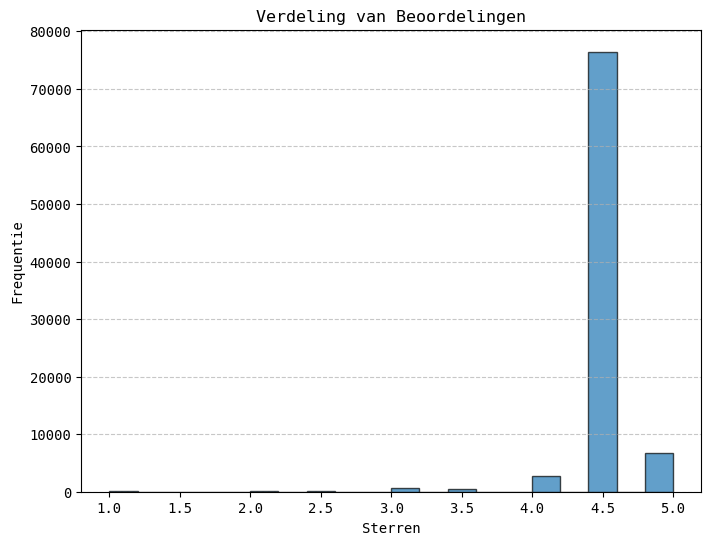

/opt/conda/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 30690 (\N{CJK UNIFIED IDEOGRAPH-77E2}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/conda/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 23798 (\N{CJK UNIFIED IDEOGRAPH-5CF6}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/conda/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 38597 (\N{CJK UNIFIED IDEOGRAPH-96C5}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/conda/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 24344 (\N{CJK UNIFIED IDEOGRAPH-5F18}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/conda/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 30707 (\N{CJK UNIFIED IDEOGRAPH-77F3}) missing from font(s) DejaV

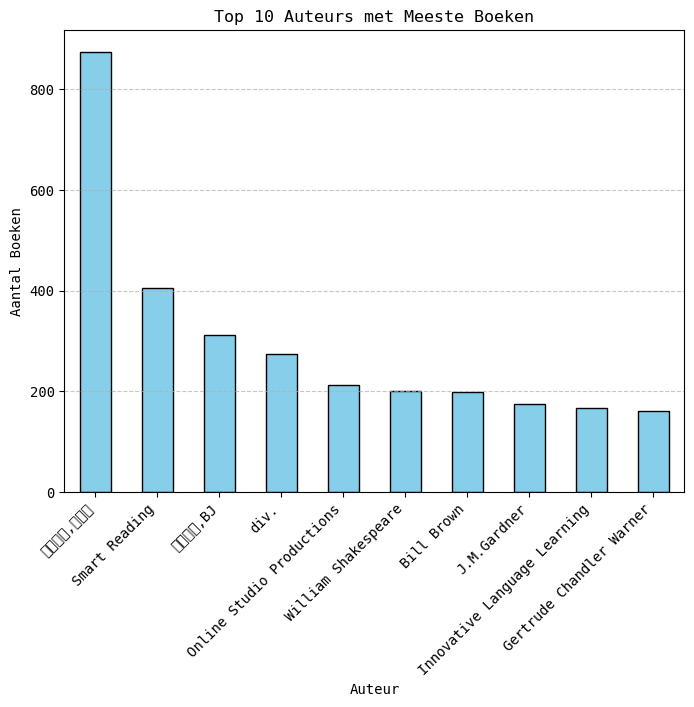

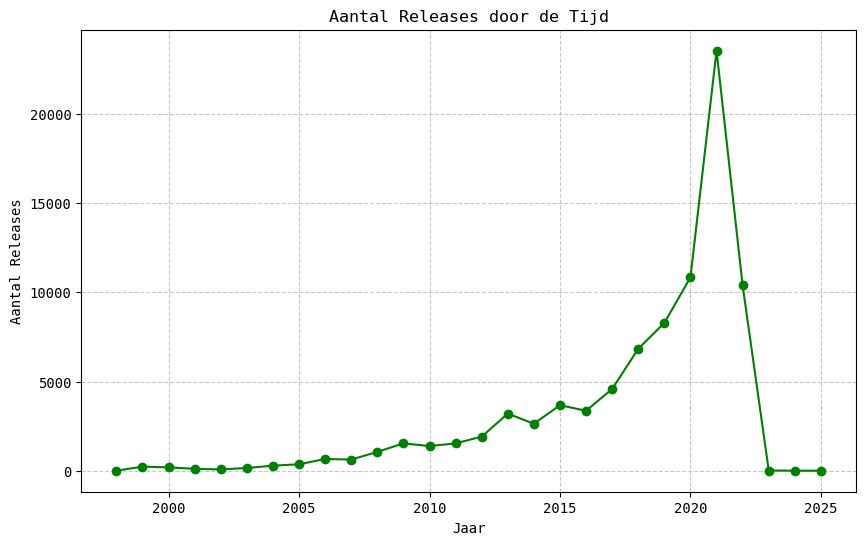

In [37]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# Stel een lettertype in dat CJK-tekens ondersteunt als je dit hebt.  Ik heb dit niet...
# plt.rcParams['font.family'] = 'Arial Unicode MS'  # Voor macOS
# plt.rcParams['font.family'] = 'SimHei'  # Voor Windows
plt.rcParams['font.family'] = 'DejaVu Sans Mono'  # Voor Linux

# Visualisatie 1: Verdeling van Beoordelingen
plt.figure(figsize=(8, 6))
df['average_rating'].plot(kind='hist', bins=20, edgecolor='black', alpha=0.7)
plt.title('Verdeling van Beoordelingen')
plt.xlabel('Sterren')
plt.ylabel('Frequentie')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Visualisatie 2: Top 10 Auteurs met Meeste Boeken
top_authors = df['author'].value_counts().head(10)
plt.figure(figsize=(8, 6))
top_authors.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Top 10 Auteurs met Meeste Boeken')
plt.xlabel('Auteur')
plt.ylabel('Aantal Boeken')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Visualisatie 3: Trend van Releases in de Tijd
release_trend = df.groupby(df['releasedate'].dt.year).size()
plt.figure(figsize=(10, 6))
release_trend.plot(kind='line', marker='o', color='green')
plt.title('Aantal Releases door de Tijd')
plt.xlabel('Jaar')
plt.ylabel('Aantal Releases')
plt.grid(axis='both', linestyle='--', alpha=0.7)
plt.show()


In [38]:
# Waarom? Visualisaties maken trends en patronen in de data beter zichtbaar.

## Stap 11: Opslaan van de Opgeschoonde Dataset
# Sla de opgeschoonde dataset op als een nieuwe CSV-file
df.to_csv("audible_cleaned.csv", index=False)

print("Datasetschoonmaak voltooid en opgeslagen als 'audible_cleaned.csv'.")

Datasetschoonmaak voltooid en opgeslagen als 'audible_cleaned.csv'.
